# HOUSE PRICE PREDICTION USING DEEP FEEDFORWARD NEURAL NETWORK (FFNN)

## Problem Type

Regression (Regression is a supervised machine learning technique used to predict continuous numerical values. In this project, regression is used to predict the selling price of a house based on various input features.)

## Dataset
Housing Price Prediction Dataset (545 Records)

## Model Family
Deep Feedforward Neural Network (FFNN) / Multi-Layer Perceptron (MLP)


---

## Project Description

This notebook presents a Deep Neural Network (DNN) model to predict house prices using the Housing Price Prediction dataset. The model learns the relationship between housing features such as area, bedrooms, bathrooms, stories, parking, furnishing status, and other attributes to estimate the selling price of a house.

---

## Objectives

- Perform data preprocessing and cleaning.
- Analyze the dataset using Exploratory Data Analysis (EDA).
- Split the dataset into training and testing datasets (80% Training, 20% Testing).
- Build a Deep Feedforward Neural Network (FFNN) using TensorFlow/Keras.
- Use Dense layers to learn complex relationships between input features and house prices.
- Train the model using the Adam optimizer and Mean Squared Error (MSE) loss function.
- Evaluate the model using MAE, MSE, RMSE, and R² Score.
- Predict the selling price of a new house.

---

## Dataset Description

**Dataset Name:** Housing Price Prediction

**Source:** Kaggle

**Number of Records:** 545

**Number of Input Features:** 12

**Target Variable:** Price

The dataset contains information about residential houses including area, number of bedrooms, bathrooms, stories, parking facilities, furnishing status, air conditioning, basement availability, and several other attributes used for predicting the selling price.


**1.imports**

# Import Required Libraries

## Definition
A software library is a collection of pre-written programs, functions, and classes that provide reusable functionality for software development. Libraries reduce development time by allowing developers to use tested and optimized implementations instead of writing code from scratch.

## Purpose
The required Python libraries are imported to perform data manipulation, visualization, preprocessing, model development, and performance evaluation.

### Libraries Used

• NumPy – Numerical computations and multidimensional array operations.

• Pandas – Data loading, manipulation, and analysis using DataFrames.

• Matplotlib – Data visualization through graphs and charts.

• Scikit-learn – Machine learning utilities including preprocessing, model evaluation, and dataset splitting.

• TensorFlow/Keras – Deep learning framework used to build, train, and evaluate the Feedforward Neural Network.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

**2.Load the dataset**

# Dataset Loading

## Definition
Dataset loading is the process of importing data from an external storage source into the computer's memory for further processing and analysis.

## Purpose
The Housing Price Prediction dataset is loaded into a Pandas DataFrame using the read_csv() function. The DataFrame provides a tabular data structure for efficient data manipulation.

In [ ]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv("Housing.csv")
print("FIRST FIVE ROWS")
print(df.head())

Saving Housing.csv to Housing (1).csv
FIRST FIVE ROWS
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  


**3.Display the information**

# Dataset Exploration

## Definition
Dataset exploration is the process of understanding the characteristics, structure, dimensions, statistical properties, and data quality of a dataset before developing a machine learning model.

## Purpose

• Determine dataset dimensions

• Identify data types

• Verify missing values

• Analyze statistical properties

• Understand feature distributions

In [ ]:
print("\nDATASET SHAPE")
print(df.shape)
print("\nDATASET INFORMATION")
df.info()
print("\nSTATISTICAL SUMMARY")
print(df.describe())


DATASET SHAPE
(545, 13)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea          545 non-null    object
 12  furnishingstatus  545 non-null    object
dtypes: int64(6), object(7)
memory usage: 55.5+ KB

STATISTICAL SUMMARY
              price          area    bedrooms   bathrooms     stories  \
count  5.45000

**4.Check the missing values**

# Missing Value Analysis

## Definition

Missing values are observations for which one or more feature values are unavailable, null, or undefined.

## Purpose

Missing value analysis is performed to ensure data quality before preprocessing. A dataset without missing values improves model reliability and prediction accuracy.

In [ ]:
print("\nMISSING VALUES")
print(df.isnull().sum())


MISSING VALUES
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


**5.Encode the categorical features**

# Label Encoding

## Definition

Label Encoding is a preprocessing technique that converts categorical data into numerical values by assigning a unique integer to each category.

## Purpose

Deep learning algorithms cannot process textual categorical variables directly. Therefore, categorical features are transformed into numerical representations before model training.

In [ ]:
encoder = LabelEncoder()
categorical_columns = [
    "mainroad",
    "guestroom",
    "basement",
    "hotwaterheating",
    "airconditioning",
    "prefarea",
    "furnishingstatus"
]
for column in categorical_columns:
    df[column] = encoder.fit_transform(df[column])
print("\nENCODED DATASET")
print(df.head())


ENCODED DATASET
      price  area  bedrooms  bathrooms  stories  mainroad  guestroom  \
0  13300000  7420         4          2        3         1          0   
1  12250000  8960         4          4        4         1          0   
2  12250000  9960         3          2        2         1          0   
3  12215000  7500         4          2        2         1          0   
4  11410000  7420         4          1        2         1          1   

   basement  hotwaterheating  airconditioning  parking  prefarea  \
0         0                0                1        2         1   
1         0                0                1        3         0   
2         1                0                0        2         1   
3         1                0                1        3         1   
4         1                0                1        2         0   

   furnishingstatus  
0                 0  
1                 0  
2                 1  
3                 0  
4                 0  


**6.Split input features and target variable**

# Feature Selection

## Definition

Input features are independent variables used by the model to predict the target variable.

The target variable is the dependent variable whose value is predicted by the machine learning model.

## Purpose

The dataset is divided into input features (X) and target variable (y) before training the neural network.

In [ ]:
X = df.drop("price", axis=1)
y = df["price"]
print("\nINPUT FEATURE SHAPE")
print(X.shape)
print("\nTARGET SHAPE")
print(y.shape)
print("\nFIRST FIVE INPUT FEATURES")
print(X.head())
print("\nFIRST FIVE TARGET VALUES")
print(y.head())


INPUT FEATURE SHAPE
(545, 12)

TARGET SHAPE
(545,)

FIRST FIVE INPUT FEATURES
   area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
0  7420         4          2        3         1          0         0   
1  8960         4          4        4         1          0         0   
2  9960         3          2        2         1          0         1   
3  7500         4          2        2         1          0         1   
4  7420         4          1        2         1          1         1   

   hotwaterheating  airconditioning  parking  prefarea  furnishingstatus  
0                0                1        2         1                 0  
1                0                1        3         0                 0  
2                0                0        2         1                 1  
3                0                1        3         1                 0  
4                0                1        2         0                 0  

FIRST FIVE TARGET VALUES
0    1330000

**7.Train-test split and Feature scaling**

# Train-Test Split

## Definition

Train-Test Split is a data partitioning technique that divides the dataset into training and testing subsets. The training set is used to learn model parameters, while the testing set is used to evaluate the model's performance on unseen data.

## Purpose

An 80:20 split is used in this project, where 80% of the data is used for training and 20% is reserved for testing.

## Feature Scaling
## Definition
Feature Scaling is a data preprocessing technique used to standardize the numerical features so that each feature contributes equally during model training.

In this project, StandardScaler transforms the data to have zero mean and unit standard deviation.

## Purpose
• Prevents features with large values from dominating learning

• Improves convergence speed

• Enhances prediction accuracy

## StandardScaler Formula

Feature scaling standardizes each feature by subtracting its mean and dividing by its standard deviation.

### Formula

$$
z = \frac{x - \mu}{\sigma}
$$

Where:

- **z** = Standardized value
- **x** = Original feature value
- **μ** = Mean of the feature
- **σ** = Standard deviation of the feature

## Train-Test Split

The dataset is divided into training and testing subsets.

### Formula

$$
Training\ Data=(1-Test\ Size)\times N
$$

$$
Testing\ Data=Test\ Size\times N
$$

Where:

- **N** = Total number of samples

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)
print("\nTraining Feature Shape :", X_train.shape)
print("Testing Feature Shape  :", X_test.shape)
print("\nTraining Target Shape :", y_train.shape)
print("Testing Target Shape  :", y_test.shape)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
print("\nFirst Five Rows of Scaled Training Data")
print(X_train[:5])
print("\nFirst Five Rows of Scaled Testing Data")
print(X_test[:5])


Training Feature Shape : (436, 12)
Testing Feature Shape  : (109, 12)

Training Target Shape : (436,)
Testing Target Shape  : (109,)

First Five Rows of Scaled Training Data
[[ 0.38416819  0.05527092  1.53917323  2.58764353  0.40715525 -0.46677307
  -0.74642003 -0.23052136  1.50124327  0.36795665 -0.55262032 -1.40940148]
 [ 0.9291807   0.05527092  1.53917323 -0.91249891  0.40715525 -0.46677307
   1.33972825 -0.23052136  1.50124327  2.70998729 -0.55262032 -0.07931697]
 [-0.60775457 -1.28351359 -0.5579503  -0.91249891  0.40715525 -0.46677307
   1.33972825 -0.23052136  1.50124327  1.53897197 -0.55262032 -1.40940148]
 [-1.15549214  0.05527092 -0.5579503   0.25421524  0.40715525 -0.46677307
   1.33972825 -0.23052136 -0.66611456 -0.80305867  1.80956067  1.25076755]
 [-0.63773026  0.05527092 -0.5579503   0.25421524  0.40715525 -0.46677307
  -0.74642003 -0.23052136 -0.66611456 -0.80305867 -0.55262032  1.25076755]]

First Five Rows of Scaled Testing Data
[[ 0.33875048  1.39405543  1.53917323  

**8.Build the deep neural network**

# Deep Feedforward Neural Network (FFNN)

## Definition

A Deep Feedforward Neural Network (FFNN) is a type of artificial neural network in which information flows sequentially from the input layer through one or more hidden layers to the output layer without forming cycles or feedback connections.

## Purpose

The FFNN learns complex nonlinear relationships between housing features and selling prices.

# Sequential Model

## Definition

Sequential is the simplest neural network model in Keras where layers are connected one after another in a linear sequence. Each layer receives input from the previous layer and passes its output to the next layer.

# Dense Layer

## Definition

A Dense Layer is a fully connected neural network layer in which every neuron is connected to every neuron in the subsequent layer. Dense layers are responsible for learning complex relationships within the input data.

# ReLU Activation Function

## Definition

The Rectified Linear Unit (ReLU) is a nonlinear activation function widely used in deep learning. It outputs the input value if it is positive; otherwise, it outputs zero.

## Purpose

ReLU introduces nonlinearity into the neural network, enabling it to learn complex patterns while reducing the vanishing gradient problem.

# Model Compilation

## Definition

Model compilation is the process of configuring the neural network for training by specifying the optimizer, loss function, and evaluation metrics.

## Purpose

The model is compiled using the Adam optimizer, Mean Squared Error loss function, and Mean Absolute Error evaluation metric.

## Dense Layer Formula

A Dense layer computes the weighted sum of the inputs and applies an activation function.

### Formula

$$
y = f(Wx + b)
$$

Where:

- **W** = Weight matrix
- **x** = Input vector
- **b** = Bias
- **f()** = Activation function
- **y** = Output

## ReLU Activation Function

The Rectified Linear Unit (ReLU) introduces non-linearity into the neural network.

### Formula

$$
ReLU(x)=\max(0,x)
$$

Meaning:

$$
ReLU(x)=
\begin{cases}
x, & x>0 \\
0, & x\le0
\end{cases}
$$

Neural Network Architecture

Input Layer

↓

Dense (64 neurons, ReLU)

↓

Dense (32 neurons, ReLU)

↓

Dense (16 neurons, ReLU)

↓

Output Layer (1 neuron)



In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
model = Sequential()
model.add(Dense(64, activation='relu', input_shape=(12,)))
model.add(Dense(32, activation='relu'))
model.add(Dense(16, activation='relu'))
model.add(Dense(1))
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,457 (13.50 KB)

 Trainable params: 3,457 (13.50 KB)

 Non-trainable params: 0 (0.00 B)

**9.Train the deep neural network model**

# Model Training

## Definition

Model training is the process in which the neural network learns the relationship between input features and target values by iteratively updating its weights through backpropagation.

## Purpose

The neural network is trained for multiple epochs using batches of training samples to minimize prediction error.

Epoch 1/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 25349387714560.0000 - mae: 4727421.5000 - val_loss: 24781592199168.0000 - val_mae: 4623896.5000
Epoch 2/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25349370937344.0000 - mae: 4727420.5000 - val_loss: 24781564936192.0000 - val_mae: 4623894.0000
Epoch 3/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25349326897152.0000 - mae: 4727415.0000 - val_loss: 24781497827328.0000 - val_mae: 4623887.5000
Epoch 4/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25349213650944.0000 - mae: 4727405.0000 - val_loss: 24781334249472.0000 - val_mae: 4623872.0000
Epoch 5/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25348978769920.0000 - mae: 4727383.0000 - val_loss: 24781007093760.0000 - val_mae: 4623841.5000
Epoch 6/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 25348492230656.0000 - mae: 4727338.5000 - val_loss: 24780373753856.0000 - val_mae: 4623782.0000
Epoch 7/100
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 2534761981

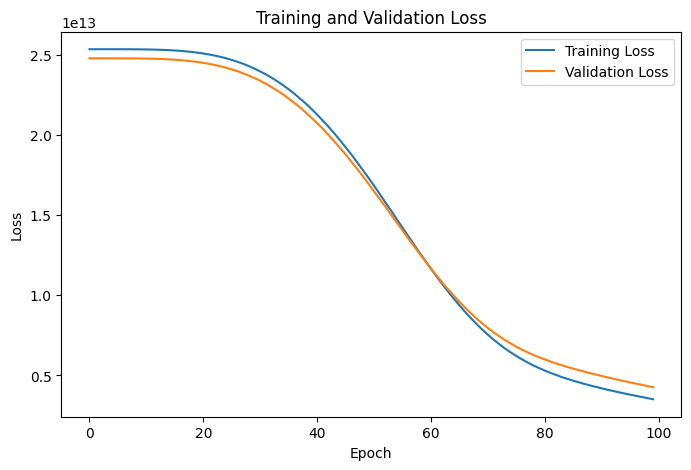

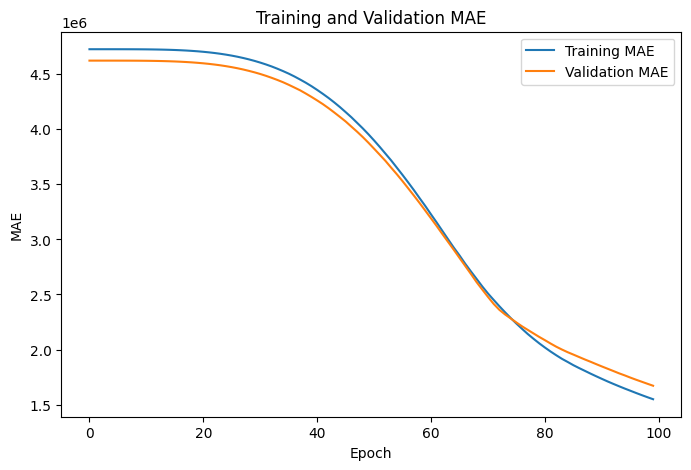

In [ ]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
plt.figure(figsize=(8,5))
plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title("Training and Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.show()

**10.Evaluate the model**

# Model Evaluation

## Definition

Model evaluation is the process of measuring the predictive performance of a trained machine learning model using statistical evaluation metrics on unseen test data.

## Purpose

Performance is evaluated using Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² Score.


## Mean Squared Error (MSE)

Mean Squared Error measures the average squared difference between the actual and predicted values.

### Formula

$$
MSE=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2
$$

Where:

- **n** = Number of observations
- **yᵢ** = Actual value
- **ŷᵢ** = Predicted value

## Mean Absolute Error (MAE)

Mean Absolute Error calculates the average absolute difference between actual and predicted values.

### Formula

$$
MAE=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|
$$

Where:

- **n** = Number of observations
- **yᵢ** = Actual value
- **ŷᵢ** = Predicted value

## Root Mean Squared Error (RMSE)

Root Mean Squared Error is the square root of Mean Squared Error.

### Formula

$$
RMSE=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
$$

or

$$
RMSE=\sqrt{MSE}
$$

## R² Score (Coefficient of Determination)

The R² Score measures how well the regression model explains the variance in the target variable.

### Formula

$$
R^2=
1-
\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}
{\sum_{i=1}^{n}(y_i-\bar{y})^2}
$$

Where:

- **yᵢ** = Actual value
- **ŷᵢ** = Predicted value
- **ȳ** = Mean of actual values

In [ ]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print("\nMODEL EVALUATION RESULTS")
print("---------------------------")
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)
print("R² Score:", r2)
print("\nFirst 10 Predictions")
for i in range(10):
    print("Actual :", y_test.iloc[i],
          " Predicted :", round(y_pred[i][0], 2))
model.save("house_price_dnn_model.keras")
print("\nModel Saved Successfully!")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step

MODEL EVALUATION RESULTS
---------------------------
Mean Absolute Error (MAE): 1810690.5
Mean Squared Error (MSE): 4810175152128.0
Root Mean Squared Error (RMSE): 2193211.1508306717
R² Score: 0.04835134744644165

First 10 Predictions
Actual : 4060000  Predicted : 907743.25
Actual : 6650000  Predicted : 7949391.5
Actual : 3710000  Predicted : 2373721.2
Actual : 6440000  Predicted : 2219191.8
Actual : 2800000  Predicted : 1806651.2
Actual : 4900000  Predicted : 2009874.2
Actual : 5250000  Predicted : 5189802.5
Actual : 4543000  Predicted : 7373147.5
Actual : 2450000  Predicted : 1558910.1
Actual : 3353000  Predicted : 1675331.6

Model Saved Successfully!


**11.Predict house price for a new house**

# House Price Prediction

## Definition

Prediction is the process of estimating the output value of unseen data using a trained machine learning model.

## Purpose

The trained FFNN receives new house features as input and predicts the estimated selling price of the house.

## Feedforward Neural Network

The output of each neuron is calculated using the following equation.

### Formula

$$
a=f\left(\sum_{i=1}^{n}w_ix_i+b\right)
$$

Where:

- **a** = Output of the neuron
- **w** = Weight
- **x** = Input
- **b** = Bias
- **f()** = Activation function

In [ ]:
import pandas as pd
print("HOUSE PRICE PREDICTION")
area = float(input("Area : "))
bedrooms = int(input("Bedrooms : "))
bathrooms = int(input("Bathrooms : "))
stories = int(input("Stories : "))
mainroad = int(input("Main Road (Yes=1 No=0): "))
guestroom = int(input("Guest Room (Yes=1 No=0): "))
basement = int(input("Basement (Yes=1 No=0): "))
hotwaterheating = int(input("Hot Water Heating (Yes=1 No=0): "))
airconditioning = int(input("Air Conditioning (Yes=1 No=0): "))
parking = int(input("Parking : "))
prefarea = int(input("Preferred Area (Yes=1 No=0): "))
furnishingstatus = int(input("Furnishing (0 Furnished, 1 Semi, 2 Unfurnished): "))
new_house = pd.DataFrame({
    "area":[area],
    "bedrooms":[bedrooms],
    "bathrooms":[bathrooms],
    "stories":[stories],
    "mainroad":[mainroad],
    "guestroom":[guestroom],
    "basement":[basement],
    "hotwaterheating":[hotwaterheating],
    "airconditioning":[airconditioning],
    "parking":[parking],
    "prefarea":[prefarea],
    "furnishingstatus":[furnishingstatus]
})
# Scale input
new_house = scaler.transform(new_house)
# Predict
prediction = model.predict(new_house, verbose=0)
print("\nPredicted House Price")
print("₹", format(prediction[0][0], ".2f"))

HOUSE PRICE PREDICTION
Area : 7432
Bedrooms : 3
Bathrooms : 2
Stories : 1
Main Road (Yes=1 No=0): 1
Guest Room (Yes=1 No=0): 0
Basement (Yes=1 No=0): 0
Hot Water Heating (Yes=1 No=0): 1
Air Conditioning (Yes=1 No=0): 1
Parking : 2
Preferred Area (Yes=1 No=0): 0
Furnishing (0 Furnished, 1 Semi, 2 Unfurnished): 1

Predicted House Price
₹ 4721430.50


# Conclusion

The House Price Prediction model was successfully developed using a Deep Feedforward Neural Network (FFNN). The dataset was preprocessed through label encoding, feature scaling, and train-test splitting before training the model. The trained model was evaluated using MAE, MSE, RMSE, and R² Score. Finally, the model predicts the selling price of a house based on its features, demonstrating the application of deep learning techniques to regression problems.

Advantages

• Predicts continuous house prices.

• Learns nonlinear relationships.

• Handles multiple input features.

• Automated prediction process.

• Reduces manual estimation effort.